# Cookie Cats A/B Test: Does Moving the First Gate from Level 30 to Level 40 Change Retention?

**Business question.** Cookie Cats is a mobile puzzle game. Players hit "gates" that force them to wait or pay to progress. The first gate was at level 30. Would moving it to level 40 improve player retention?

**Experiment design.** 90,189 players who installed the game during the test were randomly assigned to:
- `gate_30` (control): first gate at level 30
- `gate_40` (treatment): first gate at level 40

**Columns.**

| Column | Meaning |
|---|---|
| `userid` | Unique player ID |
| `version` | A/B group (`gate_30` or `gate_40`) |
| `sum_gamerounds` | Rounds played during the first 14 days after install |
| `retention_1` | Player came back 1 day after install |
| `retention_7` | Player came back 7 days after install |

**Metrics.** D1 retention and D7 retention (share of players who returned).

**Notebook outline.**
1. Load data and build the SQLite database
2. Data understanding
3. Data quality: sample ratio check and outliers
4. Distribution of rounds played
5. Retention summary
6. Hypothesis tests
7. Export for Power BI
8. Conclusion and limitations

In [16]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest

DATA_DIR = Path("../data")
EXPORT_DIR = DATA_DIR / "exports"
DB_PATH = DATA_DIR / "cookie_cats.db"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1. Load data and build the SQLite database

The raw CSV is loaded into a SQLite table so the same data can be queried with SQL in notebook `02_sql_queries`.

In [17]:
import os
print(os.getcwd())

C:\Users\sygnatec\PycharmProjects\cookie-cats-ab-test\notebooks


In [18]:
raw = pd.read_csv(DATA_DIR / "cookie_cats.csv")

conn = sqlite3.connect(DB_PATH)
raw.to_sql("cookie_cats", conn, index=False, if_exists="replace")

90189

## 2. Data understanding

In [19]:
def check_df(dataframe,head=5):
    print("##SHAPE##")
    print(dataframe.shape)
    print("##TYPE##")
    print(dataframe.dtypes)
    print("##HEAD##")
    print(dataframe.head())
    print("##NULL##")
    print(dataframe.isnull().sum())
    print("##DESCRIBE##")
    print(dataframe.describe().T)

check_df(raw)

##SHAPE##
(90189, 5)
##TYPE##
userid             int64
version           object
sum_gamerounds     int64
retention_1         bool
retention_7         bool
dtype: object
##HEAD##
   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
##NULL##
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
##DESCRIBE##
                  count          mean           std    min        25%        50%        75%        max
userid          90189.0  4.998412e+06  2.883286e+06  116.0  2512230.0  4995815.0  7496452.0  9999861.0
sum_gamerounds  90189.0  5.187246e+01  1.950509e+02    0.0        5.0       16.0       51.0    49854.0


In [20]:
print("\nDuplicate user IDs:", raw["userid"].duplicated().sum())
raw.head()


Duplicate user IDs: 0


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 3. Data quality

### 3.1 Sample ratio mismatch (SRM)

With random assignment, each group should hold about 50% of players. A chi-square goodness-of-fit test checks whether the observed split deviates more than chance would explain.

In [21]:
group_sizes = raw["version"].value_counts().sort_index()
chi2, p_srm = chisquare(group_sizes.values)  # null hypothesis: equal split

print(group_sizes.to_string())
print(f"\nShare of gate_30: {group_sizes['gate_30'] / group_sizes.sum():.2%}")
print(f"SRM check: chi2 = {chi2:.2f}, p = {p_srm:.4f}")

version
gate_30    44700
gate_40    45489

Share of gate_30: 49.56%
SRM check: chi2 = 6.90, p = 0.0086


**Result.** The split is 49.6% / 50.4% (44,700 vs 45,489 players), chi-square p = 0.0086. The deviation is statistically significant, which points to a possible sample ratio mismatch.

This does not invalidate the retention comparison, but it is a warning sign: in a live experiment, the first step would be to check how users were assigned and logged. It is listed under limitations in section 8.

### 3.2 Outliers in rounds played

In [22]:
print(raw["sum_gamerounds"].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).to_string())
print("\nFive largest values:")
print(raw["sum_gamerounds"].nlargest(5).to_string(index=False))

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
50%         16.000000
90%        134.000000
99%        493.000000
99.9%     1073.624000
max      49854.000000

Five largest values:
49854
 2961
 2640
 2438
 2294


A handful of players have extreme round counts (the maximum is far above the 99.9th percentile).

**Treatment of outliers.** Players are **capped, not removed**.
- Retention is a yes/no outcome, so extreme round counts do not affect it. Capping leaves retention untouched.
- Deleting these players would be a mistake: `sum_gamerounds` is measured *after* install and is closely tied to retention, so players with extreme values are almost all returning players. Removing them would bias retention downwards.
- Capping only matters for the average rounds metric, where one extreme player would otherwise distort the mean.

The cap is an upper fence built from the spread between the 1st and 99th percentiles.

In [23]:
df=raw.copy()

In [24]:
def outlier_thresholds(dataframe, variable):
    quartile1 = dataframe[variable].quantile(0.01)
    quartile3 = dataframe[variable].quantile(0.99)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range

    low_limit = int(round(low_limit))
    up_limit = int(round(up_limit))
    return low_limit, up_limit

def replace_with_thresholds(dataframe, variable):
    low_limit, up_limit = outlier_thresholds(dataframe, variable)
    # dataframe.loc[(dataframe[variable] < low_limit), variable] = low_limit
    dataframe.loc[(dataframe[variable] > up_limit), variable] = up_limit


df["sum_gamerounds_capped"] = df["sum_gamerounds"].copy()


_, rounds_cap = outlier_thresholds(df, "sum_gamerounds_capped")

replace_with_thresholds(df, "sum_gamerounds_capped")

n_capped = int((raw["sum_gamerounds"] > rounds_cap).sum())
print(f"Cap: {rounds_cap} rounds. Players capped: {n_capped}. Players kept: {len(df):,} (none removed).")

# Store the cap so the SQL queries use the exact same limit.
pd.DataFrame({"name": ["rounds_cap"], "value": [rounds_cap]}).to_sql(
    "analysis_params", conn, index=False, if_exists="replace"
)

Cap: 1232 rounds. Players capped: 61. Players kept: 90,189 (none removed).


1

## 4. Distribution of rounds played

Rounds played in the first 14 days are highly right-skewed, so an ECDF on a symmetric-log axis shows both casual and heavy players. The curves for the two versions should overlap if the gate position does not change overall engagement.

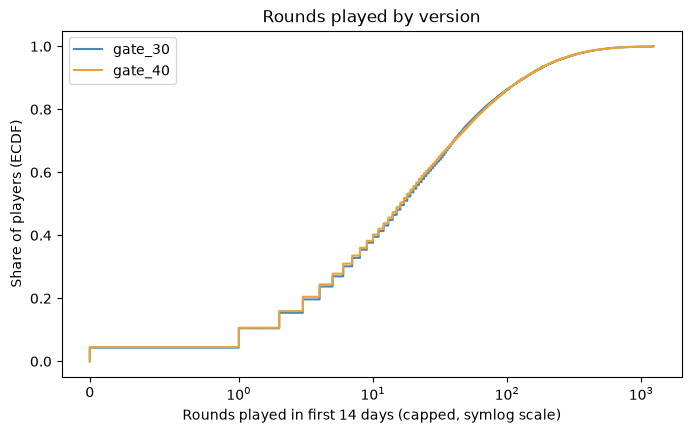

In [25]:
fig, ax = plt.subplots(figsize=(8, 4.5))

for version, color in [("gate_30", "#4C86B4"), ("gate_40", "#E8A33D")]:
    values = np.sort(df.loc[df["version"] == version, "sum_gamerounds_capped"].to_numpy())
    share = np.arange(1, len(values) + 1) / len(values)
    ax.step(values, share, where="post", label=version, color=color)

ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Rounds played in first 14 days (capped, symlog scale)")
ax.set_ylabel("Share of players (ECDF)")
ax.set_title("Rounds played by version")
ax.legend()
plt.show()

## 5. Retention summary

In [26]:
summary = (
    df.groupby("version")
    .agg(
        players=("userid", "count"),
        d1_rate=("retention_1", "mean"),
        d7_rate=("retention_7", "mean"),
        avg_rounds_capped=("sum_gamerounds_capped", "mean"),
    )
    .reset_index()
)
summary

,version,players,d1_rate,d7_rate,avg_rounds_capped
0,gate_30,44700,0.448188,0.190201,51.153087
1,gate_40,45489,0.442283,0.182000,51.065444


Both retention rates are slightly lower for `gate_40`. The next section tests whether these gaps are larger than chance.

## 6. Hypothesis tests

For each metric (D1 and D7) a **two-proportion z-test** compares treatment (`gate_40`) with control (`gate_30`).

- H0: retention is the same in both groups
- H1: retention differs between the groups (two-sided)

Reported for each metric:
- `diff_pp`: gate_40 minus gate_30, in **percentage points (pp)**, i.e. the plain gap between two percentages (44.23% - 44.82% = -0.59 pp)
- `ci_low_pp`, `ci_high_pp`: 95% confidence interval of that gap
- `relative_change_pct`: the same gap relative to the control rate

In [27]:
control = df[df["version"] == "gate_30"]
treatment = df[df["version"] == "gate_40"]


def compare_retention(day, column):
    """Two-proportion z-test of treatment (gate_40) against control (gate_30)."""
    p_control, p_treatment = control[column].mean(), treatment[column].mean()
    diff = p_treatment - p_control
    std_err = np.sqrt(
        p_control * (1 - p_control) / len(control)
        + p_treatment * (1 - p_treatment) / len(treatment)
    )
    _, p_value = proportions_ztest(
        [treatment[column].sum(), control[column].sum()],
        [len(treatment), len(control)],
    )
    return {
        "retention_day": day,
        "diff_pp": diff * 100,
        "ci_low_pp": (diff - 1.96 * std_err) * 100,
        "ci_high_pp": (diff + 1.96 * std_err) * 100,
        "p_value": p_value,
        "relative_change_pct": diff / p_control * 100,
    }


test_results = pd.DataFrame([
    compare_retention("D1", "retention_1"),
    compare_retention("D7", "retention_7"),
])
test_results["significant"] = np.where(test_results["p_value"] < 0.05, "Yes", "No")
test_results

,retention_day,diff_pp,ci_low_pp,ci_high_pp,p_value,relative_change_pct,significant
0,D1,-0.590517,-1.239256,0.058222,0.074410,-1.317566,No
1,D7,-0.820130,-1.328165,-0.312095,0.001554,-4.311903,Yes


**Multiple testing.** Two metrics are tested, so a Bonferroni-adjusted threshold of 0.05 / 2 = 0.025 is also checked.

In [28]:
alpha_adjusted = 0.05 / len(test_results)
test_results[["retention_day", "p_value"]].assign(
    significant_adjusted=test_results["p_value"] < alpha_adjusted
)

,retention_day,p_value,significant_adjusted
0,D1,0.074410,False
1,D7,0.001554,True


**Interpretation.**
- **D1:** the gap is -0.59 pp (95% CI -1.24 to +0.06 pp, p = 0.0744). The interval includes zero, so there is no statistically significant D1 difference.
- **D7:** the gap is -0.82 pp (95% CI -1.33 to -0.31 pp, p = 0.0016), a relative drop of 4.3%. The interval is entirely below zero and the result stays significant after the Bonferroni adjustment.

D1 is measured one day after install, when most players have not yet reached level 30, so few of them have met the gate. By day 7 more players have reached it, which is a plausible reason the D7 effect is clearer. This explanation is a hypothesis, not something tested here.

## 7. Export for Power BI

In [30]:
test_results.round(6).to_csv(EXPORT_DIR / "test_results.csv", index=False)
print("Saved:", EXPORT_DIR / "test_results.csv")

Saved: ..\data\exports\test_results.csv


## 8. Conclusion and limitations

**Conclusion.** Moving the first gate from level 30 to level 40 did not improve retention. D7 retention is lower by 0.82 pp (4.3% relative) with `gate_40`, while D1 shows no significant difference. **Recommendation: keep the gate at level 30**, and judge future gate-placement tests on D7 or later rather than on day 1.

**Limitations.**
- **Possible sample ratio mismatch** (section 3.1, p = 0.0086). Assignment logging should be investigated before trusting the result in production.
- **No pre-install variables** (platform, country, install date). Retention is therefore not segmented. Splitting by `sum_gamerounds` would be circular: it is measured after install and is strongly tied to retention itself.
- **Only retention is measured.** Revenue, in-app purchases and long-term retention beyond day 7 are not in the data, and a gate also affects monetisation.
- **Rounds are measured over 14 days**, while retention is measured at day 1 and day 7.

In [ ]:
conn.close()